<a href="https://colab.research.google.com/github/Jirehcode/Codveda-ML-tasks/blob/main/task-6-neural-network-churn-bigml/Neural_Network_Churn_BigML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Loading google.colab onto Drive

from google.colab import drive
import os
if not os.path.exists('/content/drive'):
   drive.mount('/content/drive')
   print('Google Drive is mounted')
else:
   print('Google Drive is already mounted')

Mounted at /content/drive
Google Drive is mounted


In [ ]:
# Loading pre-split files

train_df = pd.read_csv('/content/drive/MyDrive/Codveda Data science Task List/churn-bigml-80.csv')
test_df = pd.read_csv('/content/drive/MyDrive/Codveda Data science Task List/churn-bigml-20.csv')
train_df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# Combine temporarily to ensure identical one-hot encoding columns for train and test

df_combined = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

In [ ]:
# Handle categorical and binary features

df_combined['International plan'] = df_combined['International plan'].astype(str).str.strip().map({'Yes': 1, 'No': 0})
df_combined['Voice mail plan'] = df_combined['Voice mail plan'].astype(str).str.strip().map({'Yes': 1, 'No': 0})

In [ ]:
# encoding state column uniformly

df_combined = pd.get_dummies(df_combined, columns=['State'], drop_first=True)

In [ ]:
# Seperate back into train and test sets

train_processed = df_combined.iloc[:len(train_df)]
test_processed = df_combined.iloc[len(train_df):]

# Define features (X) and target (Y)

X_train = train_processed.drop(columns=['Churn'])
y_train = train_processed['Churn'].astype(int)

X_test = test_processed.drop(columns=['Churn'])
y_test = test_processed['Churn'].astype(int)

In [ ]:
# Train a baseline model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

# Initialize and train the model

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate performance

y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]):.4f}")

              precision    recall  f1-score   support

           0       0.94      1.00      0.97       572
           1       0.98      0.63      0.77        95

    accuracy                           0.95       667
   macro avg       0.96      0.81      0.87       667
weighted avg       0.95      0.95      0.94       667

ROC-AUC Score: 0.9252


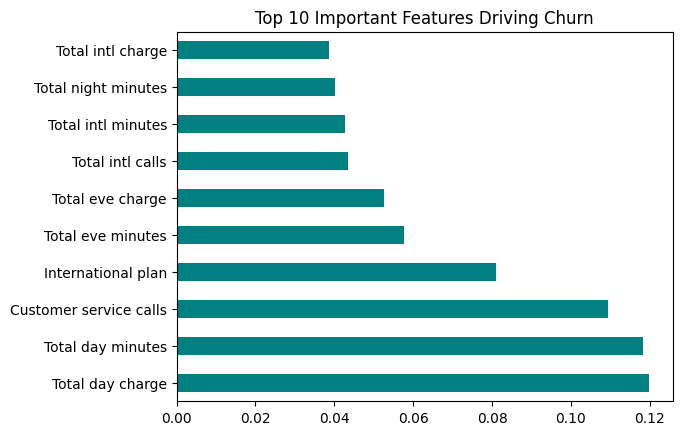

In [ ]:
# Plot features that drive customer away the most

importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Important Features Driving Churn')
plt.show()

In [ ]:
## Fix class imbalance
#Initialize with class_weight='balanced'

rf_model_balanced = RandomForestClassifier(random_state=42, class_weight='balanced')
rf_model_balanced.fit(X_train, y_train)

# Re-evaluate performance

y_pred_rf_balanced = rf_model_balanced.predict(X_test)
print(classification_report(y_test, y_pred_rf_balanced))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_model_balanced.predict_proba(X_test)[:, 1]):.4f}")

              precision    recall  f1-score   support

           0       0.93      1.00      0.97       572
           1       1.00      0.58      0.73        95

    accuracy                           0.94       667
   macro avg       0.97      0.79      0.85       667
weighted avg       0.94      0.94      0.93       667

ROC-AUC Score: 0.9212


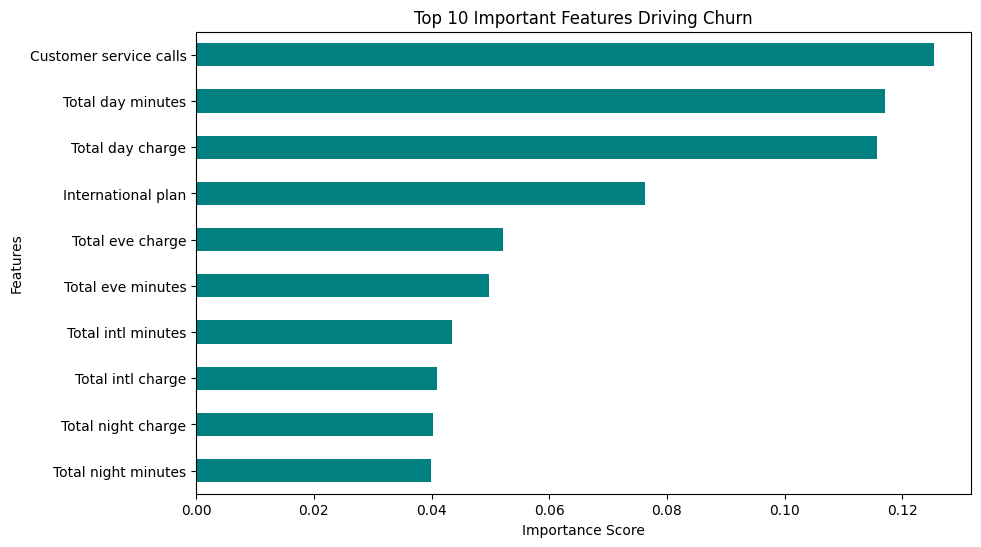

In [ ]:
# calculate importances
importances = pd.Series(rf_model_balanced.feature_importances_, index=X_train.columns)

# Plot 10 features neatly

plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Important Features Driving Churn')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Scale the features before building the neural network
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build Neural Architecture
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile And Train Model

model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Train Using Backpropagation

history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8518 - loss: 0.4377 - val_accuracy: 0.8258 - val_loss: 0.4449
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8626 - loss: 0.3908 - val_accuracy: 0.8258 - val_loss: 0.4145
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8626 - loss: 0.3556 - val_accuracy: 0.8277 - val_loss: 0.4017
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8677 - loss: 0.3447 - val_accuracy: 0.8371 - val_loss: 0.3847
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8691 - loss: 0.3213 - val_accuracy: 0.8333 - val_loss: 0.3820
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8762 - loss: 0.3083 - val_accuracy: 0.8371 - val_loss: 0.3793
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8790 - loss: 0.3009 - val_accuracy: 0.8464 - val_loss: 0.3688
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8804 - loss: 0.3001 - val_accuracy: 0.8483 - val_loss:

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9040 - loss: 0.3973
Test Loss: 0.3973
Test Accuracy: 0.9040


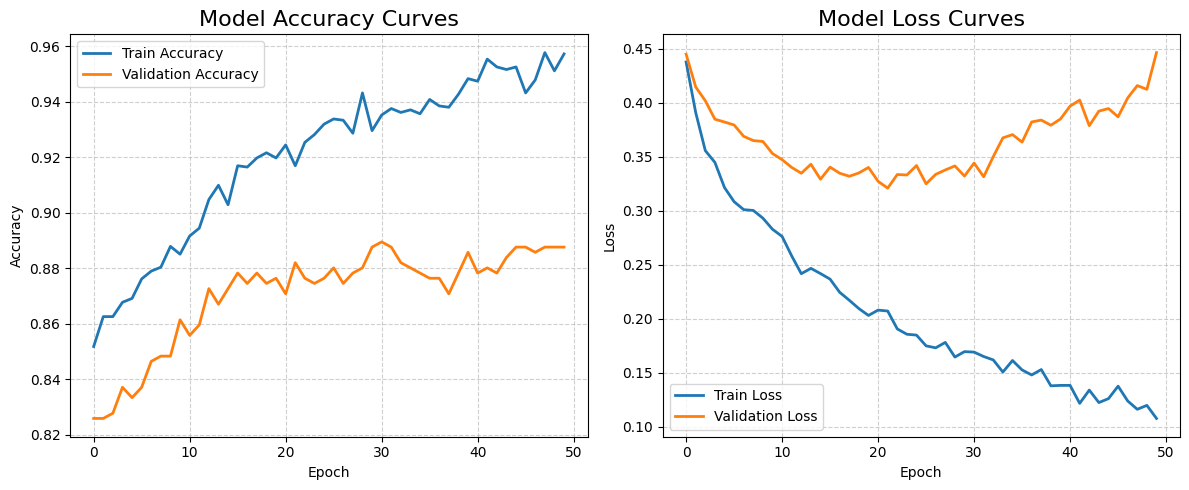

In [ ]:
###Evaluate on unseen test data(churn-bigml-20)

test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

## Plot Perfromance Curves

plt.figure(figsize=(12, 5))


#Accuracy Subplot

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Curves', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Loss Subplot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss Curves', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()